  # Daily Sales Forecasting: Store 1
  Forecasting 28 days of daily sales with naive, seasonal-naive and ETS models. SARIMA and a rolling backtest are planned.
  Data: Kaggle Store Item Demand Forecasting Challenge (train.csv).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv", parse_dates=["date"])
print(df.shape)
df.head()

(913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


<Axes: xlabel='date'>

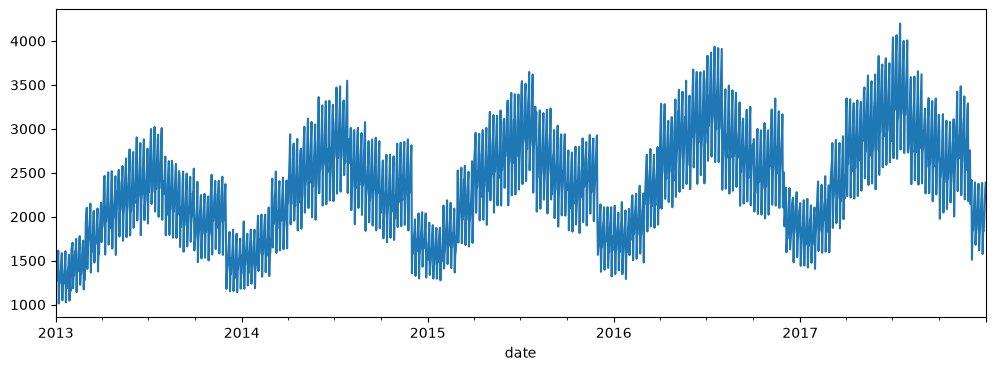

In [12]:
s = df[df.store == 1].groupby("date")["sales"].sum().asfreq("D")
s.plot(figsize=(12, 4))

Observation: Sales peak around July each year and fall to a low in December and January. The peaks rise from about 3,000 in 2013 to about 4,200 in 2017. The thick band is the weekly pattern.

Meaning: There is an upward trend plus yearly and weekly seasonality, so the series is not stationary.

Decision: Difference the series for ARIMA and use a seasonal period of 7. A period of 7 does not capture the yearly cycle, which is a limitation.

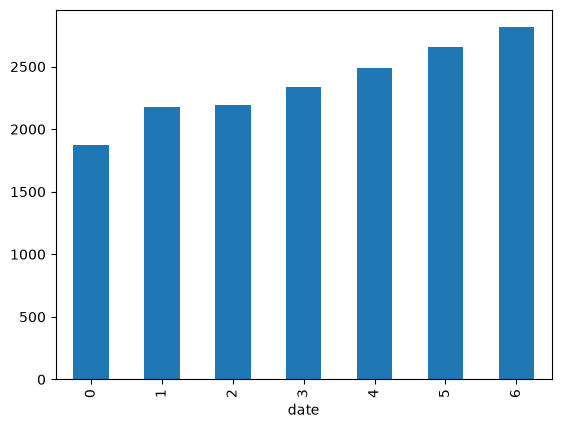

In [3]:
s.groupby(s.index.dayofweek).mean().plot(kind="bar")
plt.show()

Observation: Average sales rise steadily from Monday (about 1,900) to Sunday (about 2,800).
Meaning: There is a strong 7-day pattern with weekends the busiest.
Decision: Use a seasonal period of 7 in ETS and SARIMA.

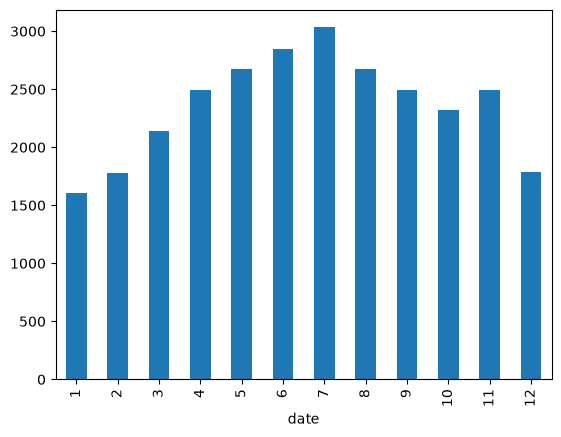

In [4]:
s.groupby(s.index.month).mean().plot(kind="bar")
plt.show()

Observation: Sales peak in July (about 3,000) and are lowest in January (about 1,600), with December also low (about 1,800). There is a small bump in November.

Meaning: There is a strong yearly cycle that a 7-day model cannot see.

Decision: This explains why the baselines over-forecast the December test window. Yearly seasonality is a next step (for example, Fourier terms).

In [5]:
from statsmodels.tsa.stattools import adfuller

d1 = s.diff().dropna()               # removes the trend
d1_7 = s.diff().diff(7).dropna()     # also removes weekly seasonality

for name, x in {"original": s, "diff(1)": d1, "diff(1)+diff(7)": d1_7}.items():
    print(f"{name}: ADF p-value = {adfuller(x, result_object=False)[1]:.4f}")


original: ADF p-value = 0.0364
diff(1): ADF p-value = 0.0000
diff(1)+diff(7): ADF p-value = 0.0000


Observation: The original series has p = 0.036, only borderline stationary. After differencing, p = 0.0000.
Meaning: The test is borderline here, but the plots clearly show trend and seasonality, so I do not rely on the test alone.
Decision: Use d = 1 and a seasonal difference D = 1 (period 7).

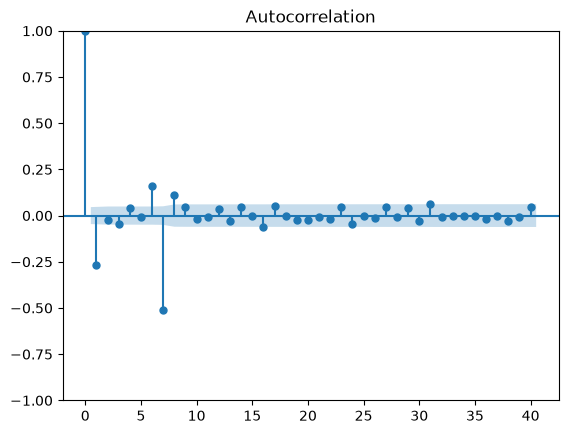

In [6]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(d1_7, lags=40)
plt.show()


Observation: Large negative spikes at lag 1 (about -0.27) and lag 7 (about -0.5), with small spikes at lags 6 and 8. Almost nothing significant after that, including at lags 14 and 21.
Meaning: The ACF cuts off after lag 1 and after the first seasonal lag, which suggests a moving-average term of order 1 and a seasonal moving-average term of order 1.
Decision: Start with q = 1 and Q = 1.

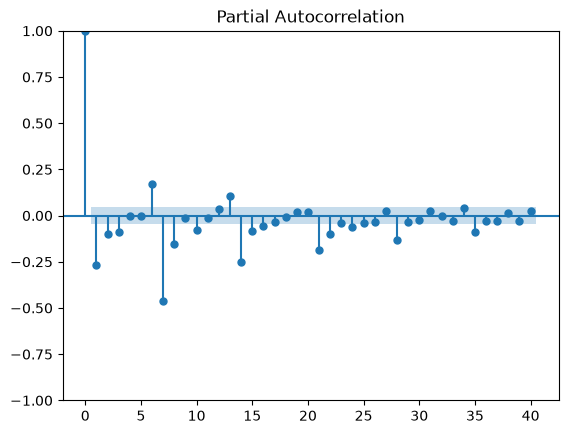

In [7]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(d1_7, lags=40, method="ywm")
plt.show()

Observation: Spikes at lag 1 (about -0.27) and at the seasonal lags 7, 14, 21 and 28, shrinking gradually (about -0.47, -0.25, -0.18, -0.13).
Meaning: A gradual decay at the seasonal lags matches a seasonal moving-average term, not a seasonal AR term.
Decision: Keep p and P small (0 or 1) and compare them in the backtest.

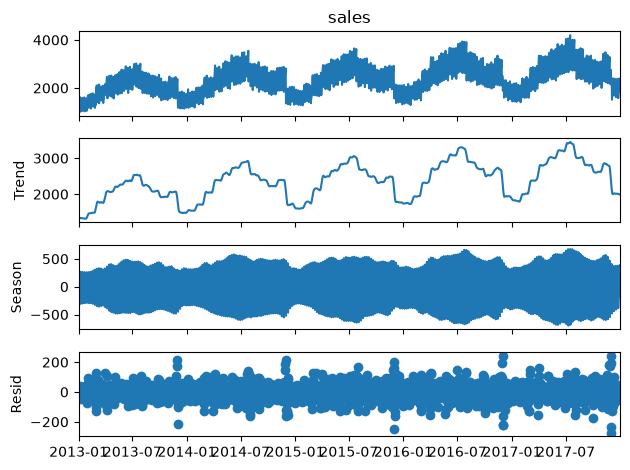

In [8]:
from statsmodels.tsa.seasonal import STL

STL(s, period=7).fit().plot()
plt.show()

Observation:  The trend follows the yearly cycle and drifts upward (peaks of about 2,500 in 2013 to about 3,400 in 2017). The weekly seasonal swing is regular, about +/-450 early and about +/-650 later. Residuals are mostly within +/-100, with a few outliers around the turn of the year.

Meaning: The weekly pattern grows a little as sales grow, so it is slightly multiplicative. An additive model is a reasonable first choice.

Decision: Use trend="add", seasonal="add" in ETS, and test seasonal="mul" in the backtest.

In [9]:
def wape(a, f): return np.abs(a - f).sum() / np.abs(a).sum()
def bias(a, f): return (f - a).sum() / a.sum()
def mase(a, f, train, m=7):
    scale = np.abs(train.values[m:] - train.values[:-m]).mean()
    return np.abs(a - f).mean() / scale

H = 28
def naive(train):          return np.repeat(train.iloc[-1], H)
def seasonal_naive(train): return np.tile(train.iloc[-7:].values, H // 7)

In [10]:
train, test = s.iloc[:-28], s.iloc[-28:]
for name, fn in {"naive": naive, "seasonal_naive": seasonal_naive}.items():
    f = fn(train)
    print(name, round(wape(test.values, f), 3), round(bias(test.values, f), 3), round(mase(test.values, f, train), 3))

naive 0.204 0.204 4.022
seasonal_naive 0.22 0.204 4.345


Observation: Naive (WAPE 20.4%) and seasonal naive (22.0%) both over-forecast by about 20%. Naive's WAPE equals its bias, so it was too high on every day of the test window. Its last training value was a Sunday, the busiest day of the week.

Meaning: The errors come mainly from the level, not the weekly shape. Sales fall from late November into December, but both baselines carry forward the higher late-November level. Seasonal naive copies the weekly shape well but at the wrong level, so it did not beat naive here.

Limitation: This is one 28-day December window. Seasonal naive may perform better in other seasons, so I will confirm with a rolling backtest.

ets 0.057 -0.042 1.13


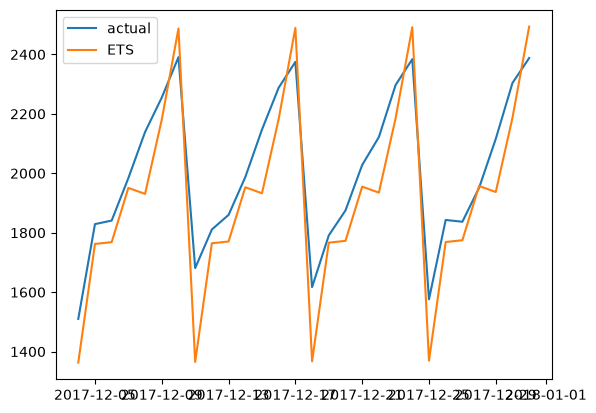

In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

m = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7).fit()
f = m.forecast(H).values
print("ets", round(wape(test.values, f), 3), round(bias(test.values, f), 3), round(mase(test.values, f, train), 3))

plt.plot(test.index, test.values, label="actual")
plt.plot(test.index, f, label="ETS")
plt.legend()
plt.show()

Observation: ETS follows the weekly shape closely. It under-forecasts overall (bias -4.2%), mostly on the Monday low points, and slightly overshoots the Sunday peaks.

Meaning: The weekly pattern is captured well, but the amplitude is a bit too large.

Limitation: this is one 28-day December holdout, not the full backtest.